In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import imblearn.over_sampling as imb

In [5]:
X_train = pd.read_csv("../data/splits/X_train.csv")
X_test = pd.read_csv("../data/splits/X_test.csv")
y_train = np.load("../data/splits/y_train.npy")
y_test = np.load("../data/splits/y_test.npy")

In [6]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(227845, 32) (227845,)
(56962, 32) (56962,)


In [7]:
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_train, y_train)


/Users/abcd/PycharmProjects/FraudShield/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [8]:
y_pred = log_reg.predict(X_test)

F1 score: 0.10830324909747292
Precision: 0.05754475703324808
Recall: 0.9183673469387755
ROC AUC: 0.9462229250169397


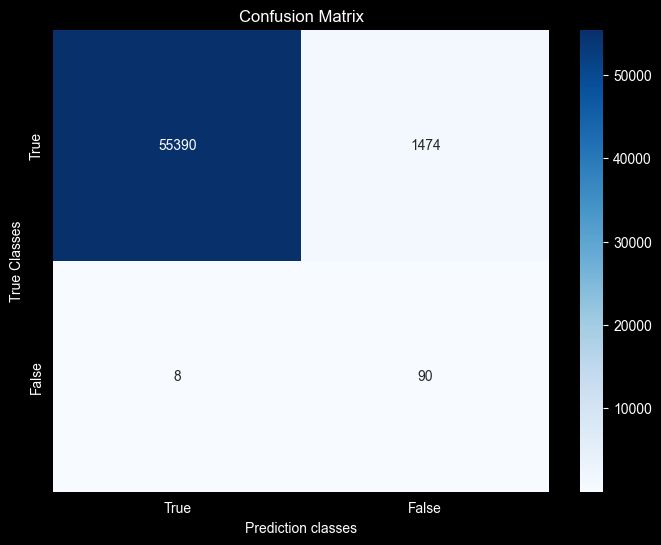

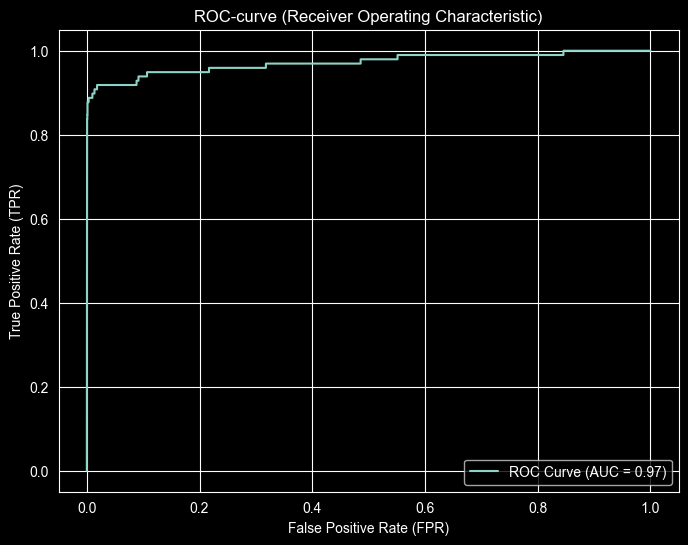

In [16]:
def metrics(model, y_test, y_pred, X_test):
    print(f"F1 score: {f1_score(y_test, y_pred)}")
    print(f"Precision: {precision_score(y_test, y_pred)}")
    print(f"Recall: {recall_score(y_test, y_pred)}")
    print(f"ROC AUC: {roc_auc_score(y_test, y_pred)}")

    # Confusion Matrix
    plt.figure(figsize=(8, 6))
    labels = ['True', 'False']
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prediction classes')
    plt.ylabel('True Classes')
    plt.title('Confusion Matrix')
    plt.show()

    #ROC-curve
    y_scores = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_scores)
    auc = roc_auc_score(y_test, y_scores)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title('ROC-curve (Receiver Operating Characteristic)')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

metrics(log_reg, y_test, y_pred, X_test)

## Logistic Regression (Baseline)

### Parameters
- `class_weight='balanced'`

### Metrics
| Metric | Score |
|--------|-------|
| F1 | 0.108 |
| Precision | 0.058 |
| Recall | 0.918 |
| ROC AUC | 0.974 |

### Confusion Matrix
- True Negatives (Legitimate → Legitimate): 55,390
- False Positives (Legitimate → Fraud): 1,474
- False Negatives (Fraud → Legitimate): 8
- True Positives (Fraud → Fraud): 90

### Interpretation
High Recall (0.92) means the model catches 92% of fraud cases — good!
Low Precision (0.06) means many false alarms — for every real fraud,
there are ~16 false positives. This is a typical trade-off when using
`class_weight='balanced'` with severe class imbalance.

In [17]:
rf = RandomForestClassifier(n_estimators=100)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

F1 score: 0.8852459016393442
Precision: 0.9529411764705882
Recall: 0.826530612244898
ROC AUC: 0.9132301344848576


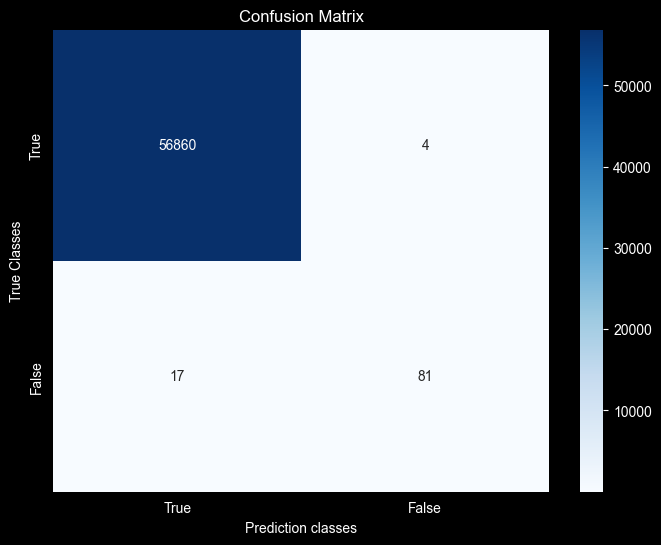

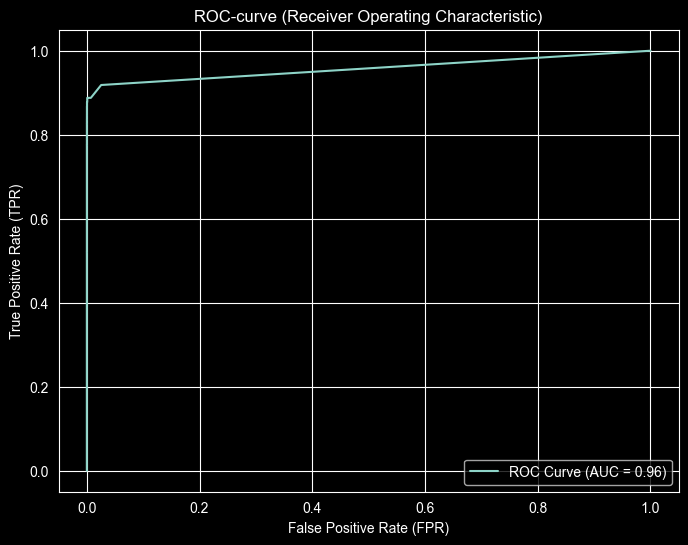

In [18]:
metrics(rf, y_test, y_pred, X_test)

## Random Forest

### Parameters
- `n_estimators=100`

### Metrics
| Metric | Score |
|--------|-------|
| F1 | 0.885 |
| Precision | 0.953 |
| Recall | 0.827 |
| ROC AUC | 0.913 |

### Confusion Matrix
- True Negatives: 56,860
- False Positives: 4
- False Negatives: 17
- True Positives: 81

### Interpretation
Massive improvement over Logistic Regression. Precision jumped from 0.06 to 0.95 —
almost no false alarms. Recall dropped slightly (0.92 → 0.83) — misses more fraud
cases. Only 4 false positives vs 1,474 for Logistic Regression.

In [22]:
scale = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(scale_pos_weight=scale)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

F1 score: 0.8601036269430051
Precision: 0.8736842105263158
Recall: 0.8469387755102041
ROC AUC: 0.9233638728423278


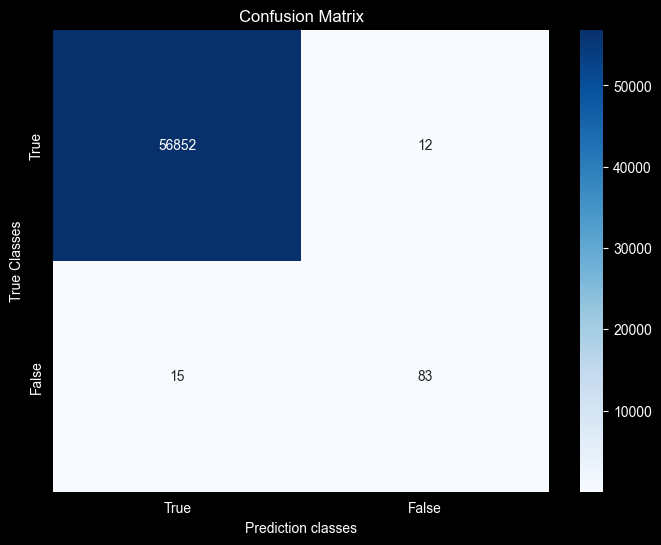

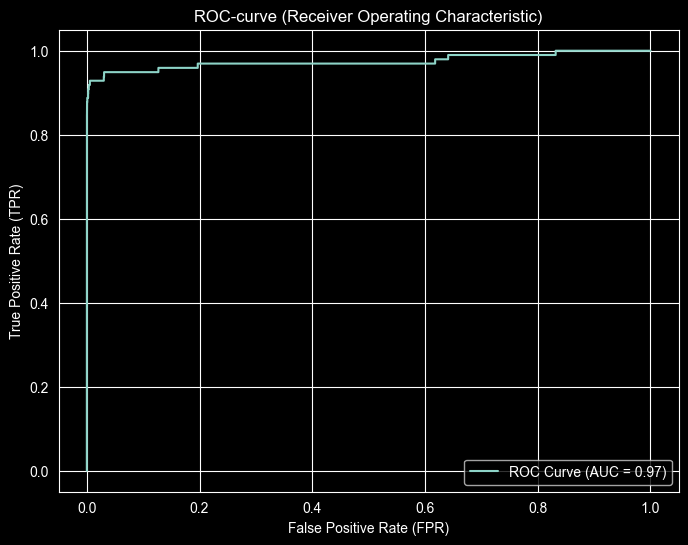

In [23]:
metrics(xgb_model, y_test, y_pred, X_test)

## XGBoost

### Parameters
- `scale_pos_weight=577` (ratio of legitimate to fraud transactions)

### Metrics
| Metric | Score |
|--------|-------|
| F1 | 0.860 |
| Precision | 0.874 |
| Recall | 0.847 |
| ROC AUC | 0.923 |

### Confusion Matrix
- True Negatives: 56,852
- False Positives: 12
- False Negatives: 15
- True Positives: 83

### Interpretation
XGBoost with default parameters performs slightly below Random Forest on F1
and Precision, but has better balance between Precision and Recall.
Hyperparameter tuning could improve results significantly.

## Model Comparison

| Metric | Logistic Regression | Random Forest | XGBoost |
|--------|---------------------|---------------|---------|
| F1 | 0.108 | **0.885** | 0.860 |
| Precision | 0.058 | **0.953** | 0.874 |
| Recall | **0.918** | 0.827 | 0.847 |
| ROC AUC | **0.974** | 0.913 | 0.923 |

### Winner: Random Forest 🏆
Random Forest outperforms on F1 and Precision with default parameters.
However, XGBoost has potential with hyperparameter tuning — we will use
Random Forest as our production model for the FastAPI endpoint and Streamlit app.